In [3]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans

In [5]:
loaded_arr = np.load('shapes_data.npy')  # 60 * 100 *100
print(loaded_arr.shape)
print(len(loaded_arr))

(60, 100, 100)
60


In [ ]:
print(loaded_arr[0])    # 0 ~ 29 네모 모양
print(loaded_arr[59])   # 30~59 세모 모양

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [7]:
np.set_printoptions(threshold=np.inf)
print(loaded_arr[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0 

In [8]:
np.set_printoptions(threshold=1000)

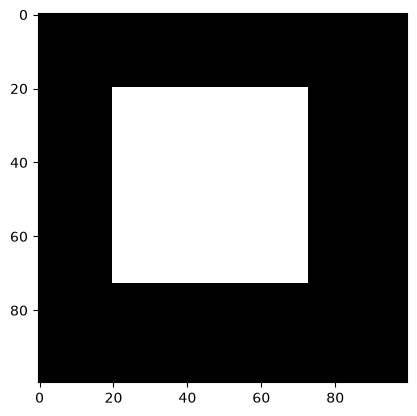

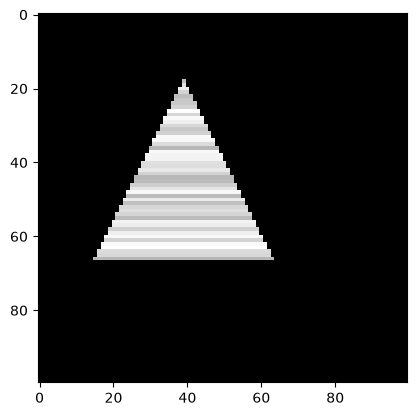

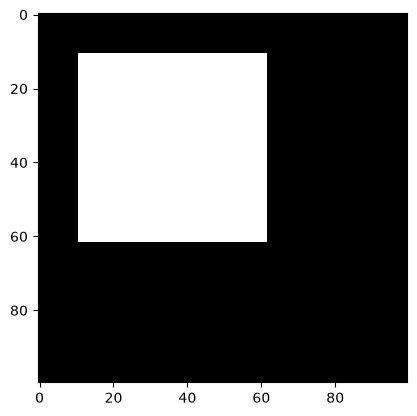

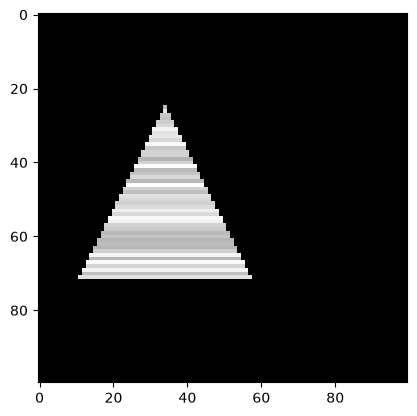

In [11]:
import matplotlib.pyplot as plt

plt.imshow(loaded_arr[0], cmap='gray')
plt.show()

plt.imshow(loaded_arr[50], cmap='gray')
plt.show()

plt.imshow(loaded_arr[29], cmap='gray')
plt.show()

plt.imshow(loaded_arr[30], cmap='gray')
plt.show()

In [ ]:
# 머신러닝 X 는 2차원(NumPy 2차원배열, [[]], 데이터프레임, ...)
# loaded_arr는 60 * 100 *100 3차원 -> 2차원 변경

In [16]:
# X = loaded_arr.reshape(60, 10000)   # loaded_arr[0][0][0] ~ loaded_arr[59][99][99]
# 60 -> len(loaded_arr)), loaded_arr.shape[0]
# 10000 -> 남은건 자동으로 계산 -1
X = loaded_arr.reshape(loaded_arr.shape[0], -1) 
print(X.shape) # 60*100*100 -> 60*10000 X[0][0] ~ X[59][9999]


(60, 10000)


In [19]:
model = KMeans(n_clusters=2)
# model.fit(X)
# print(model.labels_)
pred = model.fit_predict(X)
print(pred)

[1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 0 1 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


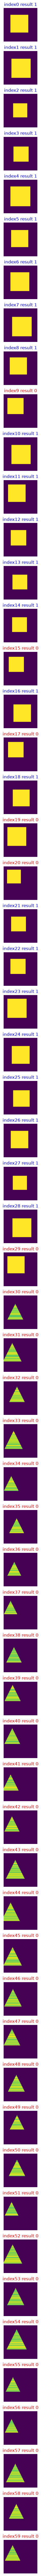

In [22]:
import matplotlib.pyplot as plt

# 2. 60행 1열 서브플롯 생성 (아래로 쭉 길게 출력)
fig, axes = plt.subplots(60, 1, figsize=(100, 100))

# 3. 반복문을 돌며 이미지 출력, 총 60개의 차트(이미지)
for i in range(60):
    ax = axes[i]  # 1차원 인덱스 직접 사용
    ax.imshow(loaded_arr[i])
    
    # 군집 번호 (0 또는 1)
    c = pred[i]
    color = "red" if c == 0 else "blue"
    
    # 제목에 간단히 번호와 0 또는 1만 표기
    ax.set_title(f'index{i} result {c}' ,color=color) # 제목에 cluster_labels 출력, 0은 빨간색으로 출려그, 1은 파란색으로 출력
    ax.axis("off") # x,y 좌표 숨기기

plt.tight_layout()
plt.show()